In [36]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, roc_auc_score, f1_score, recall_score, log_loss, confusion_matrix, ConfusionMatrixDisplay)

In [37]:
DATA_DIR = Path('../data')
if not (DATA_DIR / 'JFF_formatted_public_release_labels.csv').exists():
    DATA_DIR = Path('/mnt/data')
OUTPUT_DIR = DATA_DIR / 'ajq_onet_outputs'
OUTPUT_DIR.mkdir(exist_ok=True, parents=True)
SEED = 1234

In [38]:
# Load the respondent-level AJQ survey and occupation-level O*NET Work Values table.
df = pd.read_csv(DATA_DIR / 'JFF_formatted_public_release_labels.csv', encoding='latin1', low_memory=False)
wv_raw = pd.read_excel(DATA_DIR / 'Work Values.xlsx')

print('AJQ rows/columns:', df.shape)
print('O*NET raw rows/columns:', wv_raw.shape)

AJQ rows/columns: (18429, 153)
O*NET raw rows/columns: (7866, 9)


In [39]:
# Convert Q4 (overall job satisfaction) into a number from 0 through 10.
df_clean = df.copy()
df_clean['Q4_Numeric'] = pd.to_numeric(
    df_clean['Q4'].astype(str).str.extract(r'^(\d+)')[0], errors='coerce'
)

# Create the binary classification label
# 1 means highly satisfied (8–10); 0 means not highly satisfied (0–7).
df_clean = df_clean.loc[df_clean['Q4_Numeric'].between(0, 10)].copy()
df_clean['Highly_Satisfied'] = (df_clean['Q4_Numeric'] >= 8).astype(int)

print('Valid respondents:', len(df_clean))
print('Positive class proportion:', round(df_clean['Highly_Satisfied'].mean(), 3))

Valid respondents: 18381
Positive class proportion: 0.416


In [40]:
# O*NET uses different measurement scales; EX means Extent (how characteristic the work value is of the occupation).
work_value_cols = ['Achievement', 'Independence', 'Recognition','Relationships', 
                   'Support', 'Working Conditions']

wv_ex = wv_raw.loc[wv_raw['Scale ID'].eq('EX')].copy()

# Pivot from long format to wide format: one row per detailed O*NET occupation and one column per work value.
df_onet = wv_ex.pivot_table(
    index=['O*NET-SOC Code', 'Title'], columns='Element Name',
    values='Data Value', aggfunc='mean'
).reset_index()
df_onet.columns.name = None

# Extract portions of the SOC code so detailed occupations can be aggregated to broad groups compatible with AJQ Q6.
assert all(c in df_onet for c in work_value_cols)
df_onet['SOC_2Digit'] = df_onet['O*NET-SOC Code'].astype(str).str[:2]
df_onet['SOC_3Digit'] = df_onet['O*NET-SOC Code'].astype(str).str[:4]

assert df_onet['O*NET-SOC Code'].is_unique
print('Detailed O*NET occupations:', len(df_onet))

Detailed O*NET occupations: 874


In [41]:
# Define a dictionary from two-digit SOC major groups to AJQ Q6 labels.
# The healthcare-technicians exception uses SOC 29-2 as a rough subgroup; the category is still not an exact individual job match.
soc_to_ajq = {
    '11':'Management', '13':'Business and financial operations',
    '15':'Computer and mathematical', '17':'Architecture and engineering',
    '19':'Life, physical, and social science', '21':'Community and social service',
    '23':'Legal', '25':'Educational instruction and library',
    '27':'Arts, design, entertainment, sports, and media',
    '29':'Healthcare practitioners', '31':'Healthcare support',
    '33':'Protective service', '35':'Food preparation and service',
    '37':'Building and grounds cleaning and maintenance',
    '39':'Personal care and service', '41':'Sales and related',
    '43':'Office and administrative support',
    '45':'Farming, fishing, and forestry', '47':'Construction and extraction',
    '49':'Installation, maintenance, and repair', '51':'Production',
    '53':'Transportation and material moving'
}

# NOTE: Missing Q6, "Something else", and Military remain unmatched.
df_onet['AJQ_Category'] = df_onet['SOC_2Digit'].map(soc_to_ajq)
df_onet.loc[df_onet['SOC_3Digit'].eq('29-2'), 'AJQ_Category'] = 'Healthcare technicians'

In [42]:
# Aggregate individual O*NET occupations into a single average work-value profile for each AJQ occupation group.
df_onet_aggregated = (
    df_onet.dropna(subset=['AJQ_Category'])
    .groupby('AJQ_Category', as_index=False)[work_value_cols].mean()
)

# Count the O*NET occupations within each group to show how broad its average is.
counts = (df_onet.dropna(subset=['AJQ_Category'])
          .groupby('AJQ_Category')['O*NET-SOC Code']
          .nunique().rename('onet_occupation_count').reset_index())

df_onet_aggregated = df_onet_aggregated.merge(counts, on='AJQ_Category', validate='one_to_one')

# Prefix O*NET predictor names to prevent collisions with AJQ survey fields.
onet_feature_names = ['ONET_' + v.replace(' ', '_') for v in work_value_cols]
df_onet_aggregated = df_onet_aggregated.rename(columns=dict(zip(work_value_cols, onet_feature_names)))

# Merge without filtering on Q6
df_merged = df_clean.merge(
    df_onet_aggregated, how='left', left_on='Q6', right_on='AJQ_Category',
    validate='many_to_one', indicator='merge_status'
)
assert len(df_merged) == len(df_clean), 'Unexpected row multiplication during merge!'

# Rename O*NET columns with ONET_ prefixes so they are unambiguous after merging.
# Use a left join so each AJQ respondent remains in the dataset
df_merged['onet_matched'] = df_merged[onet_feature_names].notna().all(axis=1)
df_merged['match_level'] = np.where(df_merged['onet_matched'], 'SOC group aggregate', 'Unmatched')

# Flag unmatched respondents, inspect coverage, then save the merged data and occupation-level crosswalk.
print('Merged rows:', len(df_merged))
print('Match rate:', f"{df_merged['onet_matched'].mean():.2%}")
print('Unmatched Q6 categories:')
print(df_merged.loc[~df_merged['onet_matched'], 'Q6'].value_counts(dropna=False).to_string())
print('\nOccupational crosswalk coverage:')

display(df_onet_aggregated[['AJQ_Category','onet_occupation_count']].sort_values('AJQ_Category'))

# Preserve the original survey columns AND occupational estimates for later analysis.
df_merged.to_csv(OUTPUT_DIR / 'ajq_onet_merged.csv', index=False)
df_onet_aggregated.to_csv(OUTPUT_DIR / 'ajq_onet_crosswalk_aggregates.csv', index=False)

Merged rows: 18381
Match rate: 99.38%
Unmatched Q6 categories:
Q6
Something else (please specify):    65
Military                            32
No response                         17

Occupational crosswalk coverage:


,AJQ_Category,onet_occupation_count
0,Architecture and engineering,55
1,"Arts, design, entertainment, sports, and media",38
2,Building and grounds cleaning and maintenance,8
3,Business and financial operations,43
4,Community and social service,14
5,Computer and mathematical,29
6,Construction and extraction,61
7,Educational instruction and library,57
8,"Farming, fishing, and forestry",12
9,Food preparation and service,16


In [43]:
# Create a crosswalk containing every AJQ occupation category
ajq_crosswalk = pd.DataFrame({
    "AJQ_Q6": df["Q6"].dropna().unique()
})

# Attach the corresponding O*NET aggregate information
ajq_crosswalk = ajq_crosswalk.merge(df_onet_aggregated, left_on="AJQ_Q6", right_on="AJQ_Category",
    how="left", validate="one_to_one"
)

# Classify the level of occupational matching
ajq_crosswalk["match_type"] = np.where(ajq_crosswalk["AJQ_Category"].notna(), "aggregate", "unmapped")

# Display the crosswalk
display(ajq_crosswalk[ ["AJQ_Q6", "AJQ_Category", "match_type", "onet_occupation_count"]].sort_values("AJQ_Q6")
)

# Save the crosswalk
ajq_crosswalk.to_csv(OUTPUT_DIR / "ajq_onet_crosswalk.csv", index=False)

,AJQ_Q6,AJQ_Category,match_type,onet_occupation_count
17,Architecture and engineering,Architecture and engineering,aggregate,55.0
20,"Arts, design, entertainment, sports, and media","Arts, design, entertainment, sports, and media",aggregate,38.0
0,Building and grounds cleaning and maintenance,Building and grounds cleaning and maintenance,aggregate,8.0
1,Business and financial operations,Business and financial operations,aggregate,43.0
21,Community and social service,Community and social service,aggregate,14.0
2,Computer and mathematical,Computer and mathematical,aggregate,29.0
3,Construction and extraction,Construction and extraction,aggregate,61.0
8,Educational instruction and library,Educational instruction and library,aggregate,57.0
25,"Farming, fishing, and forestry","Farming, fishing, and forestry",aggregate,12.0
18,Food preparation and service,Food preparation and service,aggregate,16.0


In [44]:
# Create EDA dataset before selecting modeling features
df_eda = df_merged.copy()

# Display dataset dimensions
print("Number of respondents:", df_eda.shape[0])
print("Number of columns:", df_eda.shape[1])

# Display all columns and their data types
display(pd.DataFrame({
    "Feature": df_eda.columns,
    "Data Type": df_eda.dtypes.astype(str).values
}))

# Check duplicate rows
print("Duplicate rows:", df_eda.duplicated().sum())

# Verify merge did not change respondent count
print("AJQ respondents before merge:", len(df_clean))
print("Respondents after merge:", len(df_eda))

assert len(df_clean) == len(df_eda)

Number of respondents: 18381
Number of columns: 166


,Feature,Data Type
0,ENTITY_ID,int64
1,SAMPLE,str
2,MODE,str
3,RESPONDENT_DATE,str
4,EndDate,str
...,...,...
161,ONET_Working_Conditions,float64
162,onet_occupation_count,float64
163,merge_status,category
164,onet_matched,bool


Duplicate rows: 0
AJQ respondents before merge: 18381
Respondents after merge: 18381


In [45]:
# Replace common survey nonresponse labels
df_eda = df_eda.replace(r"^\s*$", np.nan, regex=True)

df_eda = df_eda.replace(["No response", "Not sure", "Not applicable"],np.nan)

# Preserve the original merged dataset
# All EDA changes are applied only to df_eda

In [46]:
# Calculate missing values for every column
missing_summary = pd.DataFrame({
    "Missing Count": df_eda.isna().sum(),
    "Missing Percent": df_eda.isna().mean() * 100
})

missing_summary = missing_summary.sort_values("Missing Percent",ascending=False)

display(missing_summary)

,Missing Count,Missing Percent
RACE3,18235,99.205702
RACE2,18121,98.585496
RACE4,17808,96.882651
RACE5,17625,95.887057
Q49_TEXT,17139,93.243023
...,...,...
Q9,0,0.000000
Q5,0,0.000000
Q4,0,0.000000
MODE,0,0.000000


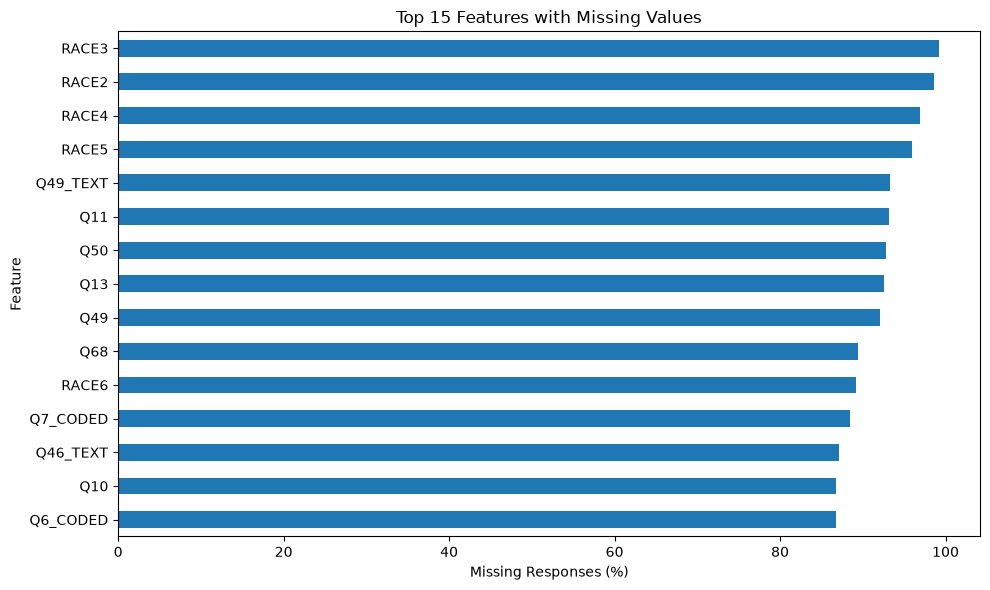

In [47]:
plt.figure(figsize=(10, 6))

missing_summary["Missing Percent"].head(15).sort_values().plot(kind="barh")

plt.xlabel("Missing Responses (%)")
plt.ylabel("Feature")
plt.title("Top 15 Features with Missing Values")
plt.tight_layout()
plt.show()

In [48]:
# Binary satisfaction class balance
print("Satisfaction class counts:")
display(df_eda["Highly_Satisfied"].value_counts())

print("Satisfaction class percentages:")
display((df_eda["Highly_Satisfied"].value_counts(normalize=True) * 100).round(2))

Satisfaction class counts:


Highly_Satisfied
0    10736
1     7645
Name: count, dtype: int64

Satisfaction class percentages:


Highly_Satisfied
0    58.41
1    41.59
Name: proportion, dtype: float64

In [49]:
# Count respondents by AJQ occupation
occupation_counts = df_eda["Q6"].value_counts(dropna=False)

display(occupation_counts)

# Check occupational matching
print("O*NET match coverage:")
display(df_eda["onet_matched"].value_counts(dropna=False))

print("\nMatch coverage percentage:")
print(round(df_eda["onet_matched"].mean() * 100, 2), "%")

Q6
Educational instruction and library               2026
Management                                        1976
Business and financial operations                 1901
Office and administrative support                 1470
Computer and mathematical                         1263
Sales and related                                 1202
Healthcare practitioners                           953
Healthcare support                                 732
Transportation and material moving                 690
Arts, design, entertainment, sports, and media     649
Architecture and engineering                       644
Production                                         572
Community and social service                       551
Legal                                              546
Installation, maintenance, and repair              545
Food preparation and service                       433
Life, physical, and social science                 405
Personal care and service                          368
Constru

O*NET match coverage:


onet_matched
True     18267
False      114
Name: count, dtype: int64


Match coverage percentage:
99.38 %


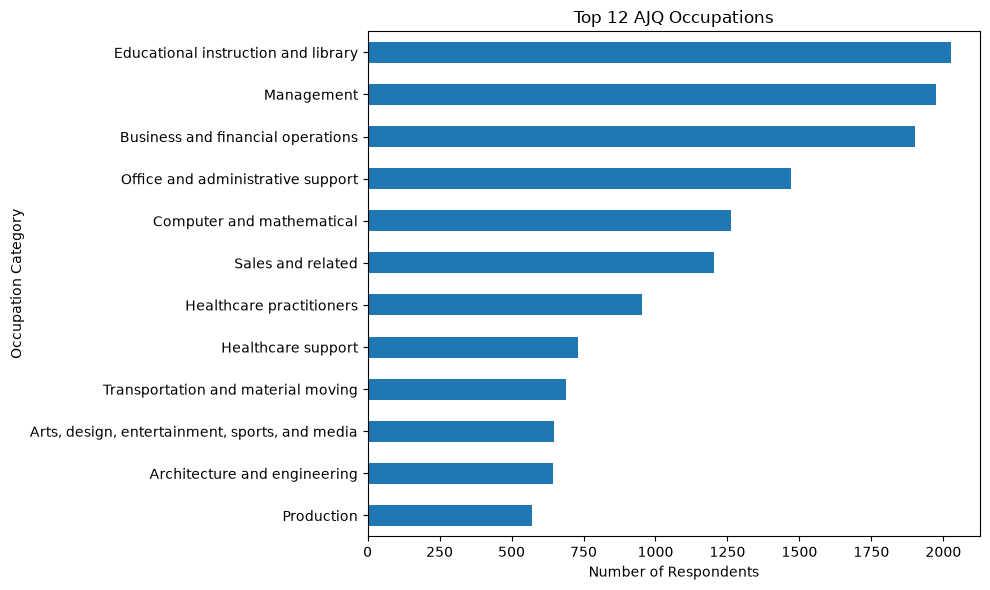

In [50]:
plt.figure(figsize=(10, 6))

occupation_counts.head(12).sort_values().plot(kind="barh")

plt.xlabel("Number of Respondents")
plt.ylabel("Occupation Category")
plt.title("Top 12 AJQ Occupations")
plt.tight_layout()
plt.show()

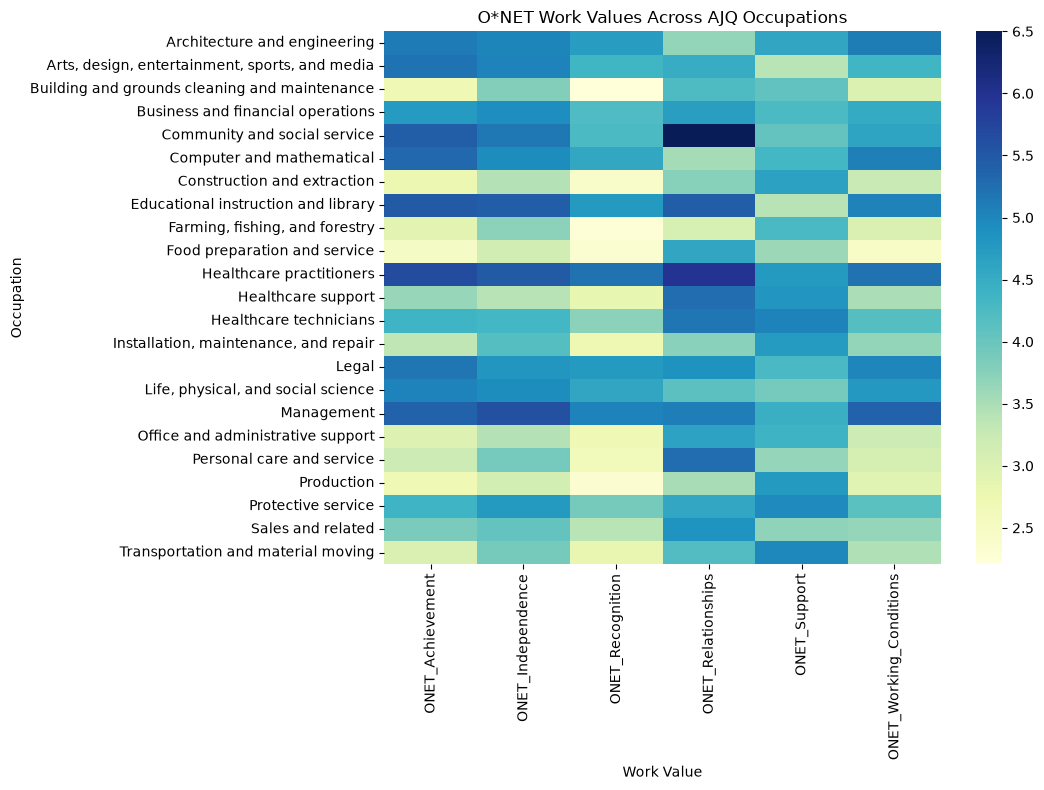

In [51]:
# Calculate average O*NET values for each AJQ occupation
onet_by_occupation = (df_eda.groupby("Q6")[onet_feature_names].mean().dropna(how="all"))
plt.figure(figsize=(11, 8))
sns.heatmap(onet_by_occupation,cmap="YlGnBu",annot=False)

plt.title("O*NET Work Values Across AJQ Occupations")
plt.xlabel("Work Value")
plt.ylabel("Occupation")
plt.tight_layout()
plt.show()